# 06 - Eksperimen F1: max-centering fusion berbasis v2

**Pertanyaan:** Apa yang berubah ketika skor kontrol tim absolut tidak lagi memberi bonus otomatis pada state Live?

**Satu intervensi:** `fusion.control_normalization: max`. Prior live tetap **0.55**, seluruh bobot evidence, fitur kontrol, biaya temporal, refinement dan video mengikuti v2. Eksperimen ini terpisah dari perubahan prior pada config v3.

F1 mengurangi kedua skor kontrol berbobot dengan maksimum per frame, lalu menambahkan utility Live. Selisih H-A dipertahankan, sedangkan utility tim terbaik sama dengan weighted live utility di luar forced-D. Ini bukan kalibrasi probabilitas atau bukti peningkatan spellF1.

Seluruh perhitungan model berada di src. Notebook menjalankan pipeline atau membuka run yang sudah selesai, lalu membaca artefaknya. Tidak memakai public/private GT. Notebook 05 dan baseline tidak ditimpa.


## 1. Config dan pemeriksaan baseline

Config F1 harus sama dengan snapshot canonical v2, kecuali opsi max-centering. Perbedaan lain menghentikan analisis agar perubahan perilaku tidak salah diatribusikan ke fusion.


In [1]:
from pathlib import Path
from copy import deepcopy
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'games.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.artifacts import list_runs, read_json, read_table
from src.pipeline import run_pipeline
from src.submission import segments_for_labels
BASE_RUN_ID = '20261115_152745_650609_05d95801'
base_dir = next(Path(r['path']) for r in list_runs(project_dir=ROOT) if r['run_id'] == BASE_RUN_ID)
base_manifest = read_json(base_dir)
base_config = read_json(base_dir, 'config/model.json')
MODEL_CONFIG = ROOT / 'config/f1.yaml'
STORAGE_CONFIG = ROOT / 'config/artifacts_f1.yaml'
f1_config = yaml.safe_load(MODEL_CONFIG.read_text(encoding='utf-8-sig'))
check = deepcopy(f1_config)
assert check['fusion'].pop('control_normalization') == 'max'
assert check == base_config, 'F1 is not an isolated change from the selected v2 run'
assert f1_config['live_dead']['live_prior_score'] == 0.55
print('Baseline:', BASE_RUN_ID)
print('F1 intervention: fusion.control_normalization none -> max')
display(f1_config['fusion'])
display(yaml.safe_load(STORAGE_CONFIG.read_text(encoding='utf-8-sig')))


Baseline: 20261115_152745_650609_05d95801
F1 intervention: fusion.control_normalization none -> max


{'control_normalization': 'max',
 'dead_bias': 0.0,
 'dead_weight': 1.0,
 'live_weight': 1.0,
 'second_half_kickoff_frame': 113742,
 'team_weight': 1.0}

{'root_dir': 'artifacts', 'submission_filename': 'baseline_f1.csv'}

## 2. Jalankan F1 atau buka run yang sudah selesai

Run contoh sudah selesai. Default `RUN_F1=False` membuka hasil tersebut tanpa menjalankan ulang tracking. Ubah menjadi True untuk membuat run baru; setiap eksekusi akan mendapat folder unik. `F1_RUN_ID` dapat diisi untuk memilih run tertentu. Pengaturan penyimpanan tetap terpisah dari model.


In [2]:
RUN_F1 = False
F1_RUN_ID = '20261115_232213_442294_bf05582d'
if RUN_F1:
    result = run_pipeline(f1_config, project_dir=ROOT, storage_config_path=STORAGE_CONFIG,
        execution_metadata={'experiment':'F1_max_center_v2', 'parent_run_id':BASE_RUN_ID,
            'notebook':'notebooks/06_f1_fusion_experiment.ipynb', 'model_config_source':str(MODEL_CONFIG)})
    f1_dir = Path(result.artifact_dir)
else:
    candidates = [r for r in list_runs(project_dir=ROOT)
        if read_json(r['path'], 'config/model.json').get('fusion', {}).get('control_normalization', 'none') == 'max']
    if not candidates:
        raise RuntimeError('No completed F1 run. Execute with RUN_F1=True first.')
    f1_dir = (Path(candidates[-1]['path']) if F1_RUN_ID is None else
              next(Path(r['path']) for r in candidates if r['run_id'] == F1_RUN_ID))
f1_manifest = read_json(f1_dir)
assert f1_manifest['status'] == 'completed'
assert read_json(f1_dir, 'config/model.json') == f1_config
base_pass, f1_pass = base_manifest['final_core_pass'], f1_manifest['final_core_pass']
print('F1 run:', f1_manifest['run_id'], '| core:', f1_pass)
print('Folder:', f1_dir)
display(read_json(f1_dir, 'submission/write/result.json'))
display(read_json(f1_dir, 'submission/validator/result.json'))


F1 run: 20261115_232213_442294_bf05582d | core: initial
Folder: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\artifacts\20261115_232213_442294_bf05582d


{'bytes': 1682773,
 'path': 'C:\\Users\\HP 840\\Documents\\Hizkia '
         'ITS\\Lomba\\MBG\\more-than-a-hack-mbg\\artifacts\\20261115_232213_442294_bf05582d\\submission\\baseline_f1.csv',
 'rows': 199319,
 'sha256': 'eaf703d992402779eda76a497c113be2c2fe49384a819f3873b37e5d2ddf54e3'}

{'message': 'OK    baseline_f1.csv\n'
            '      199319 rows, frame 0..199318\n'
            '\n'
            '      label counts\n'
            '        H    96146   48.2%\n'
            '        A    59714   30.0%\n'
            '        D     2997    1.5%\n'
            '        X    40462   20.3%\n'
            '\n'
            '      reports 1070 possessions of mean 5.8 s\n'
            '      (counted with each X as a gap; the scorer bridges '
            'abstentions inside a real\n'
            '       possession, so its count can be lower than this one)\n'
            '\n'
            'Valid. Note this checks the format only -- it says nothing about '
            'whether the labels are right.\n'
            'Score it against the public ground truth with run_evaluation.py.',
 'status': 'passed'}

## 3. Verifikasi isolasi dan sifat matematis

Fitur, quality, control, live/dead dan event sebelum fusion harus tetap ekuivalen. Jika hash berbeda, nilai tabel diperiksa secara langsung. Join frame memerlukan kunci unik dan cakupan yang identik. Forced-D dikeluarkan dari perbandingan utility alami.

Yang diuji: selisih H-A tetap, maksimum H/A sama dengan weighted live utility, D utility tidak berubah, dan forced-D tetap sama. Perubahan label decoded masih mungkin terjadi karena D ikut bersaing dalam jalur temporal bersama.


In [3]:
upstream_paths = [
    ('features/initial/frames.csv','features/initial/frames.csv'),
    ('features/initial/events.csv','features/initial/events.csv'),
    ('features/initial/slots.csv','features/initial/slots.csv'),
    (f'core/{base_pass}/quality/frames.csv',f'core/{f1_pass}/quality/frames.csv'),
    (f'core/{base_pass}/control/frames.csv',f'core/{f1_pass}/control/frames.csv'),
    (f'core/{base_pass}/control/scores.csv',f'core/{f1_pass}/control/scores.csv'),
    (f'core/{base_pass}/live_dead/frames.csv',f'core/{f1_pass}/live_dead/frames.csv'),
    (f'core/{base_pass}/events/frames.csv',f'core/{f1_pass}/events/frames.csv'),
    (f'core/{base_pass}/fusion/transition_hint.csv',f'core/{f1_pass}/fusion/transition_hint.csv')]
isolation=[]
for bp,cp in upstream_paths:
    same_hash = base_manifest['files'][bp]['sha256'] == f1_manifest['files'][cp]['sha256']
    if not same_hash:
        pd.testing.assert_frame_equal(read_table(base_dir,bp),read_table(f1_dir,cp),check_exact=True,check_dtype=False)
    isolation.append({'artifact':cp,'same_sha256':same_hash,'values_equivalent':True})
display(pd.DataFrame(isolation))

def join_frame(base, table):
    table=table.sort_values('frame')
    assert table.frame.is_unique
    assert np.array_equal(base.frame.to_numpy(),table.frame.to_numpy()), 'Frame coverage mismatch'
    assert not ((set(base.columns)&set(table.columns))-{'frame'}), 'Column collision'
    return base.merge(table,on='frame',validate='one_to_one',how='left',sort=False)

features = read_table(f1_dir,'features/initial/frames.csv')
evidence = features[['frame','half','graded','ball_ok','set_piece_tag']].copy().sort_values('frame')
assert np.array_equal(evidence.frame.to_numpy(),np.arange(len(evidence)))
evidence = join_frame(evidence,read_table(base_dir,f'core/{base_pass}/fusion/state_log_scores.csv').rename(
    columns={'H':'base_H','A':'base_A','D':'base_D'}))
evidence = join_frame(evidence,read_table(f1_dir,f'core/{f1_pass}/fusion/state_log_scores.csv').rename(
    columns={'H':'f1_H','A':'f1_A','D':'f1_D'}))
evidence = join_frame(evidence,read_table(f1_dir,f'core/{f1_pass}/fusion/control_components.csv'))
evidence = join_frame(evidence,read_table(base_dir,'result/labels.csv').rename(columns={'label':'base_label'}))
evidence = join_frame(evidence,read_table(f1_dir,'result/labels.csv').rename(columns={'label':'f1_label'}))
natural = evidence.graded & ~evidence.forced_d
unforced = ~evidence.forced_d
np.testing.assert_allclose((evidence.f1_H-evidence.f1_A)[unforced],(evidence.base_H-evidence.base_A)[unforced],rtol=0,atol=1e-12)
np.testing.assert_allclose(evidence[['f1_H','f1_A']].max(axis=1)[unforced],evidence.live_utility[unforced],rtol=0,atol=1e-12)
np.testing.assert_allclose(evidence.f1_D,evidence.base_D,rtol=0,atol=1e-12)
np.testing.assert_allclose(evidence[['relative_control_H','relative_control_A']].max(axis=1),0,rtol=0,atol=1e-12)
np.testing.assert_allclose((evidence.f1_H-evidence.base_H)[unforced],-evidence.common_offset[unforced],rtol=0,atol=1e-12)
np.testing.assert_array_equal(evidence.loc[evidence.forced_d,['f1_H','f1_A','f1_D']],
                              evidence.loc[evidence.forced_d,['base_H','base_A','base_D']])
print('PASS: upstream equivalence; H-A gap preserved; best team equals live; D utility and forced-D unchanged.')
display(read_json(f1_dir,f'core/{f1_pass}/fusion/metadata.json'))


PASS: upstream equivalence; H-A gap preserved; best team equals live; D utility and forced-D unchanged.


,artifact,same_sha256,values_equivalent
0,features/initial/frames.csv,True,True
1,features/initial/events.csv,True,True
2,features/initial/slots.csv,True,True
3,core/initial/quality/frames.csv,True,True
4,core/initial/control/frames.csv,True,True
5,core/initial/control/scores.csv,True,True
6,core/initial/live_dead/frames.csv,True,True
7,core/initial/events/frames.csv,True,True
8,core/initial/fusion/transition_hint.csv,True,True


{'control_components_semantics': 'weighted channels before forced-D override',
 'control_normalization': 'max',
 'control_order': ['H', 'A'],
 'order': ['H', 'A', 'D'],
 'score_semantics': 'uncalibrated additive utilities'}

## 4. Perbandingan perilaku, bukan accuracy

Pisahkan D alami dari interval kickoff wajib. Jumlah possession dapat berubah karena stoppage membelah run tim yang sama; itu bukan otomatis fragmentasi yang lebih baik/buruk. Preferensi lokal H/A dipertahankan, tetapi keputusan decoded H/A bisa berubah melalui kompetisi dengan D.

`natural_D_utility_wins` adalah jumlah frame ketika D menang secara lokal. `natural_D_frames` adalah jumlah frame D setelah decoding/refinement. Keduanya tidak harus sama karena decoder mempertimbangkan seluruh urutan dan biaya transisi.


,graded_frames,natural_D_utility_wins,natural_D_frames,D_segments_total,HA_spells,HA_spells_lt_2s,HA_transitions,median_HA_duration_s,total_transitions,shifted_boundaries
model,,,,,,,,,,
v2,158857,0,0,1,1070,523,1068,2.04,1069,115
F1,158857,169,63,2,1070,523,1067,2.04,1070,116


f1_label,A,D,H
base_label,,,
A,59713,0,0
H,1,63,96146


,count,mean,std,min,5%,50%,95%,99%,max
v2,155923.0,-1.233802,0.699897,-2.706399,-2.260336,-1.347058,-0.354429,-0.340000,-0.002716
F1,155923.0,-0.447585,0.130253,-0.640000,-0.640000,-0.420000,-0.305320,-0.107146,0.277576


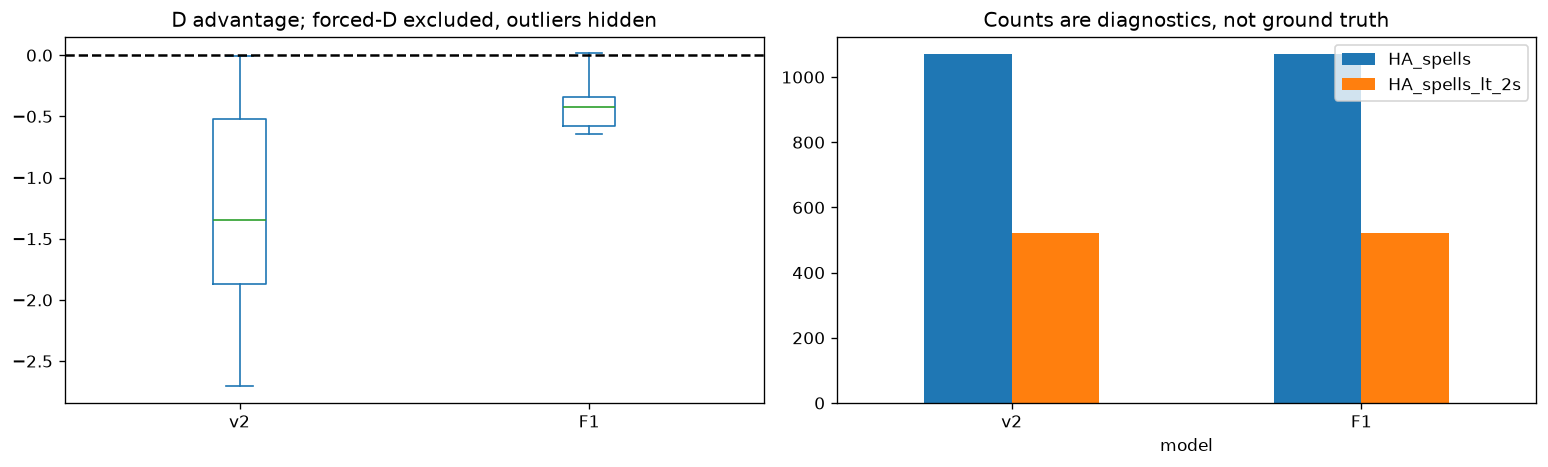

In [4]:
comparison=[]
for name,run_dir,pass_name,label_col in [('v2',base_dir,base_pass,'base_label'),('F1',f1_dir,f1_pass,'f1_label')]:
    diag=read_json(run_dir,'submission/diagnostics.json')
    core=read_json(run_dir,f'diagnostics/{pass_name}/core/dead_score_summary.json')
    segment_summary=read_table(run_dir,'diagnostics/final/prediction/segment_summary.csv')
    ha=segment_summary.loc[segment_summary.label.isin(['H','A'])]
    transitions=read_table(run_dir,'diagnostics/final/prediction/transition_counts.csv')
    ha_trans=transitions['from'].isin(['H','A']) & transitions['to'].isin(['H','A'])
    comparison.append({'model':name,'graded_frames':diag['graded_frames'],
        'natural_D_utility_wins':core['dead_wins_unforced'],
        'natural_D_frames':int(evidence.loc[natural,label_col].eq('D').sum()),
        'D_segments_total':diag['dead_segments'],'HA_spells':diag['possession_spells'],
        'HA_spells_lt_2s':int(ha.segments_lt_2s.sum()),'HA_transitions':int(transitions.loc[ha_trans,'count'].sum()),
        'median_HA_duration_s':diag['possession_median_s'],'total_transitions':diag['total_transitions'],
        'shifted_boundaries':diag['boundaries_shifted']})
comparison=pd.DataFrame(comparison).set_index('model')
display(comparison)
display(pd.crosstab(evidence.loc[natural,'base_label'],evidence.loc[natural,'f1_label']))
base_adv=evidence.base_D-evidence[['base_H','base_A']].max(axis=1)
f1_adv=evidence.f1_D-evidence[['f1_H','f1_A']].max(axis=1)
display(pd.DataFrame({'v2':base_adv[natural],'F1':f1_adv[natural]}).describe(percentiles=[.05,.5,.95,.99]).T)
fig,axes=plt.subplots(1,2,figsize=(13,4))
pd.DataFrame({'v2':base_adv[natural],'F1':f1_adv[natural]}).plot.box(ax=axes[0],showfliers=False)
axes[0].axhline(0,color='black',ls='--');axes[0].set_title('D advantage; forced-D excluded, outliers hidden')
comparison[['HA_spells','HA_spells_lt_2s']].plot.bar(ax=axes[1],rot=0)
axes[1].set_title('Counts are diagnostics, not ground truth')
plt.tight_layout();plt.show()


## 5. Interval D alami dan evidence lokal

Ekstraksi segmen memakai helper src yang sudah ada, hanya pada blok graded tanpa forced-D. Interval ini adalah prediksi algoritma, bukan stoppage yang telah diverifikasi. Jendela grafik dipilih otomatis berdasarkan D advantage alami terbesar, bukan anotasi manual pertandingan.


,half,start_frame,end_frame,duration_s,ball_observed_fraction,set_piece_context_fraction,any_stoppage_anchor,any_restart_anchor,mean_out_of_pitch_hint
0,1,44259,44321,2.52,1.0,0.730159,True,False,1.0


count    1.00
mean     2.52
std       NaN
min      2.52
25%      2.52
50%      2.52
75%      2.52
max      2.52

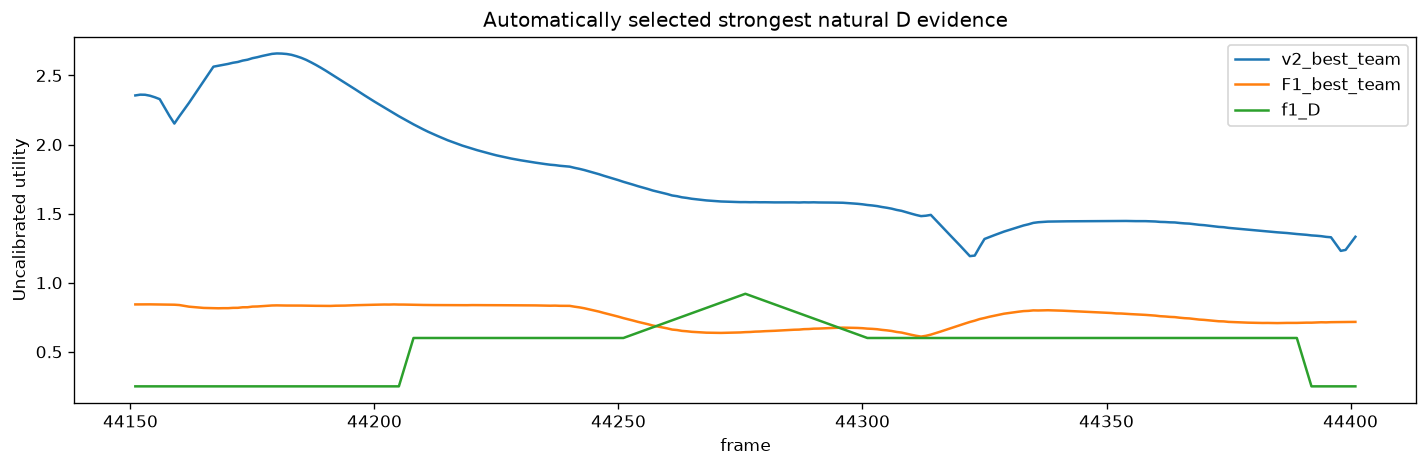

In [5]:
fps=float(f1_config['fps'])
natural_half=np.where(natural,evidence.half.to_numpy(),0)
for half in [1,2]:
    ids=np.flatnonzero(natural_half==half)
    assert len(ids)==0 or np.all(np.diff(ids)==1), 'Natural half is not contiguous'
f1_natural_segments=segments_for_labels(evidence.f1_label.to_numpy(),natural_half,fps)
base_natural_segments=segments_for_labels(evidence.base_label.to_numpy(),natural_half,fps)
f1_dead=f1_natural_segments.loc[f1_natural_segments.label.eq('D')].copy()
event_context=read_table(f1_dir,f'core/{f1_pass}/events/frames.csv')
context=join_frame(evidence,event_context)
context_rows=[]
for r in f1_dead.itertuples(index=False):
    g=context.loc[context.frame.between(r.start_frame,r.end_frame)]
    context_rows.append({'half':r.half,'start_frame':r.start_frame,'end_frame':r.end_frame,
        'duration_s':r.duration_s,'ball_observed_fraction':g.ball_ok.mean(),
        'set_piece_context_fraction':g.set_piece_tag.mean(),
        'any_stoppage_anchor':bool(g.stoppage_anchor.gt(0).any()),
        'any_restart_anchor':bool(g.restart_anchor.gt(0).any()),
        'mean_out_of_pitch_hint':g.out_of_pitch_hint.mean()})
dead_context=pd.DataFrame(context_rows,columns=['half','start_frame','end_frame','duration_s',
    'ball_observed_fraction','set_piece_context_fraction','any_stoppage_anchor','any_restart_anchor','mean_out_of_pitch_hint'])
display(dead_context)
if len(dead_context):
    display(dead_context.duration_s.describe())
else:
    print('No predicted natural D intervals survived temporal inference.')
peak=int(f1_adv[natural].idxmax());center=int(evidence.loc[peak,'frame']);half=int(evidence.loc[peak,'half'])
window=evidence.loc[evidence.half.eq(half)&evidence.frame.between(center-125,center+125)&~evidence.forced_d].copy()
window['v2_best_team']=window[['base_H','base_A']].max(axis=1)
window['F1_best_team']=window[['f1_H','f1_A']].max(axis=1)
window.plot(x='frame',y=['v2_best_team','F1_best_team','f1_D'],figsize=(12,4),title='Automatically selected strongest natural D evidence')
plt.ylabel('Uncalibrated utility');plt.tight_layout();plt.show()


## 6. Interpretasi dan arah keputusan

| Amati | Jika hasilnya seperti ini | Arah berikutnya |
|---|---|---|
| Pemeriksaan matematis | H/A gap tetap, D tetap, best H/A sama dengan Live | Mekanisme F1 sesuai rancangan; belum merupakan klaim performa |
| Utility D vs label final | D menang lokal tetapi tidak ada interval yang bertahan | Audit akumulasi keuntungan, biaya jalur dan persistensi evidence |
| Durasi D | Banyak pulsa singkat | Kandidat D1: evidence stoppage temporal; bukan sekadar menaikkan bias |
| Konteks D | Muncul terutama ketika informasi tidak tersedia | Audit prior/observability; missing ball bukan stoppage |
| Jumlah H/A | Bertambah setelah muncul D | Pisahkan pemecahan oleh stoppage dari flicker H/A langsung |
| Synthetic tests | Perilaku penting mengalami regresi | Revisi/tolak kandidat sebelum adopsi |

F1 tidak digabung dengan perubahan decoder, prior, acquisition, atau asumsi durasi event. Jangan memilih parameter dari skor public GT atau mengejar jumlah possession tertentu.


In [6]:
natural_D_frames=int(comparison.loc['F1','natural_D_frames'])
local_D_wins=int(comparison.loc['F1','natural_D_utility_wins'])
if natural_D_frames==0:
    next_step='D dapat bersaing lokal tetapi belum ada interval alami yang bertahan; audit durasi evidence dan biaya jalur sebelum mengubah bobot lagi.'
else:
    next_step='Interval D alami mulai muncul. Periksa durasi/konteks sebelum adopsi; hasil ini belum membuktikan deteksi stoppage benar.'
display(Markdown(f"**Hasil F1:** {local_D_wins:,} frame alami memiliki D sebagai utility tertinggi; "
    f"{natural_D_frames:,} frame alami berlabel final D, dalam {len(f1_dead):,} interval. {next_step} "
    "Selisih utility H/A tetap; perubahan label final perlu dibaca sebagai hasil jalur temporal bersama."))
print('Baseline run:',BASE_RUN_ID)
print('F1 run:',f1_manifest['run_id'])


Baseline run: 20261115_152745_650609_05d95801
F1 run: 20261115_232213_442294_bf05582d


**Hasil F1:** 169 frame alami memiliki D sebagai utility tertinggi; 63 frame alami berlabel final D, dalam 1 interval. Interval D alami mulai muncul. Periksa durasi/konteks sebelum adopsi; hasil ini belum membuktikan deteksi stoppage benar. Selisih utility H/A tetap; perubahan label final perlu dibaca sebagai hasil jalur temporal bersama.

## 7. Pemeriksaan D1 - episode D positif yang ditolak atau dipertahankan

**Pertanyaan:** Apakah peluang D hilang karena bukti singkat, biaya masuk/keluar, atau karena jalur H/A yang digantikan lebih menguntungkan?

**Ruang lingkup:** diagnosis pada run F1 yang sudah selesai, tanpa mengubah model/config, membuat run baru, menulis label, atau memakai GT. Jalankan bagian 1-6 dengan `RUN_F1=False` terlebih dahulu.

Episode kandidat adalah rangkaian frame graded alami dengan `u_D - max(u_H,u_A) > 1e-9`. Ini kondisi algoritmik, bukan label stoppage. Audit memakai decoded labels sebelum boundary refinement.

Untuk setiap episode, bandingkan jalur decoded dengan alternatif diagnostik yang mengganti episode itu saja menjadi D, sementara label di luar episode tetap. Hitung selisih utility, seluruh biaya transisi lama yang terdampak (termasuk H/A internal), dan biaya alternatif. Alternatif ini tidak disimpan sebagai prediksi.

`net_gain = emission_gain + old_transition_cost - replacement_transition_cost`.

Net gain negatif berarti penggantian episode tersebut merugikan objective lokal. Jika ada nilai positif, periksa indeks, kode, dan postprocessing sebelum menyebut decoder salah.


In [7]:
from functools import lru_cache
import hashlib, ast
from src.features import _runs
from src.temporal_decoder import state_cost_matrix, transition_costs

# Data yang dipakai sama dengan run F1, dengan join frame tervalidasi.
d1 = context.copy()
q = read_table(f1_dir, f'core/{f1_pass}/quality/frames.csv')
d1 = join_frame(d1, q[['frame','ball_observed','ball_weight','ball_motion_reliable','motion_reliable','observation_weight']])
ld = read_table(f1_dir, f'core/{f1_pass}/live_dead/frames.csv')
d1 = join_frame(d1, ld[['frame','live_score','dead_score','player_motion_evidence','has_player_motion']])
d1 = join_frame(d1, read_table(f1_dir, f'core/{f1_pass}/decode/labels.csv').rename(columns={'label':'decoded_label'}))
for name in ['transition_hint','stop_hint','restart_hint']:
    d1 = join_frame(d1, read_table(f1_dir, f'core/{f1_pass}/fusion/{name}.csv'))
assert np.array_equal(d1.frame.to_numpy(), np.arange(len(d1)))
d1_cfg = read_json(f1_dir, 'config/model.json')
d1_fps = float(d1_cfg['fps'])
d1_natural = d1.graded & ~d1.forced_d
d1['dead_advantage'] = d1.f1_D - d1[['f1_H','f1_A']].max(axis=1)
d1['positive_D'] = d1_natural & d1.dead_advantage.gt(1e-9)
d1['dead_dynamic_bonus'] = d1.dead_score - d1_cfg['live_dead']['dead_prior_score']
d1['live_dynamic_bonus'] = d1.live_score - d1_cfg['live_dead']['live_prior_score']
d1_decode_diag = read_json(f1_dir, f'core/{f1_pass}/decode/diagnostics.json')

# Audit only calls these two cost functions. Their AST hashes were verified
# against HEAD source whose whole-file hash matches the immutable F1 snapshot.
# Decoder dispatch has since evolved; unrelated module additions must not break
# this historical objective audit. A change to either cost function still fails.
d1_hashes = {k.replace(chr(92),'/'):v for k,v in f1_manifest['source_sha256'].items()}
d1_expected_cost_hashes = {
    'state_cost_matrix':'a15e6fcf2c223f17bc18fdccf707fa4e58e8899ceeb1ca6872821fb3c986e6fc',
    'transition_costs':'741b0ee03909aac9f22146345e50cf098db46cf41cc6e9d9b4c0d3b4f02d0f5e'}
d1_tree = ast.parse((ROOT/'src/temporal_decoder.py').read_text(encoding='utf-8'))
for name,expected in d1_expected_cost_hashes.items():
    node = next(n for n in d1_tree.body if isinstance(n,ast.FunctionDef) and n.name==name)
    actual = hashlib.sha256(ast.dump(node,include_attributes=False).encode()).hexdigest()
    assert actual==expected,name+' differs from historical F1 cost logic'
print('PASS: historical transition-cost functions unchanged; saved F1 paths are audited.')
if hashlib.sha256((ROOT/'src/live_dead.py').read_bytes()).hexdigest() != d1_hashes['src/live_dead.py']:
    print('Live/dead source has evolved; this historical audit reads saved F1 scores and does not rerun the new scorer.')
d1_base_cost = state_cost_matrix(d1_cfg['temporal'])
d1_hint_values = d1[['transition_hint','stop_hint','restart_hint']].to_numpy(float)
d1_scores = d1[['f1_H','f1_A','f1_D']].to_numpy(float)
d1_halves = d1.half.to_numpy(int)
d1_codes = d1.decoded_label.map({'H':0,'A':1,'D':2}).fillna(-1).to_numpy(int)
@lru_cache(maxsize=None)
def d1_cost_matrix(t):
    turn,stop,restart = d1_hint_values[int(t)]
    return transition_costs(d1_base_cost,float(turn),float(stop),float(restart),d1_cfg['temporal'])

def d1_replace_with_dead(start,end):
    # Objective diagnostic only: decoded labels are never mutated.
    start,end=int(start),int(end)
    assert 0 <= start <= end < len(d1)
    assert np.all(d1_halves[start:end+1] == d1_halves[start]) and d1_halves[start] != 0
    assert d1_natural.iloc[start:end+1].all()
    idx=np.arange(start,end+1);old=d1_codes[idx]
    assert (old>=0).all()
    emission=float((d1_scores[idx,2]-d1_scores[idx,old]).sum())
    old_cost=new_cost=0.;old_internal_ha=0
    for t in range(start,end+2):
        if t==0 or t>=len(d1) or d1_halves[t]==0 or d1_halves[t]!=d1_halves[t-1]:continue
        prev,curr=int(d1_codes[t-1]),int(d1_codes[t]);assert prev>=0 and curr>=0
        matrix=d1_cost_matrix(t)
        old_cost += float(matrix[prev,curr])
        new_prev=2 if start<=t-1<=end else prev
        new_curr=2 if start<=t<=end else curr
        new_cost += float(matrix[new_prev,new_curr])
        old_internal_ha += int(start<t<=end and prev in (0,1) and curr in (0,1) and prev!=curr)
    return {'emission_gain':emission,'old_transition_cost':old_cost,
            'replacement_transition_cost':new_cost,'transition_cost_saving':old_cost-new_cost,
            'net_gain':emission+old_cost-new_cost,'original_internal_HA_changes':old_internal_ha}

d1_episode_rows=[]
for half in [1,2]:
    ids=np.flatnonzero(d1_halves==half)
    if not len(ids):continue
    lo,hi=int(ids[0]),int(ids[-1])
    for start,end in _runs(d1.positive_D.iloc[lo:hi+1].to_numpy(bool),lo):
        g=d1.iloc[start:end+1]
        row={'half':half,'start_frame':start,'end_frame':end,'n_frames':end-start+1,
             'duration_s':(end-start+1)/d1_fps,'gain_vs_best_HA':g.dead_advantage.sum(),
             'decoded_D_fraction':g.decoded_label.eq('D').mean(),'final_D_fraction':g.f1_label.eq('D').mean(),
             'ball_observed_fraction':g.ball_observed.mean(),'any_stoppage_anchor':g.stoppage_anchor.gt(0).any(),
             'any_restart_anchor':g.restart_anchor.gt(0).any(),'outside_hint_fraction':g.out_of_pitch_hint.gt(0).mean()}
        row.update(d1_replace_with_dead(start,end));d1_episode_rows.append(row)
d1_episodes=pd.DataFrame(d1_episode_rows,columns=['half','start_frame','end_frame','n_frames','duration_s',
    'gain_vs_best_HA','decoded_D_fraction','final_D_fraction','ball_observed_fraction',
    'any_stoppage_anchor','any_restart_anchor','outside_hint_fraction','emission_gain',
    'old_transition_cost','replacement_transition_cost','transition_cost_saving','net_gain','original_internal_HA_changes'])
assert int(d1_episodes.n_frames.sum()) == int(d1.positive_D.sum())
d1_episodes['outcome']=np.select([d1_episodes.decoded_D_fraction.eq(0),d1_episodes.decoded_D_fraction.eq(1)],
    ['fully_suppressed','fully_in_decoded_D'],default='partly_in_decoded_D')
display(d1_episodes)
display(d1_episodes.groupby('outcome').agg(episodes=('start_frame','size'),positive_frames=('n_frames','sum'),
    median_duration_s=('duration_s','median'),max_duration_s=('duration_s','max'),
    median_net_gain=('net_gain','median'),max_net_gain=('net_gain','max')))
print('Explicit post-Viterbi merges:',d1_decode_diag['short_runs_merged'])
print('Positive local replacement gains (>1e-7):',int(d1_episodes.net_gain.gt(1e-7).sum()))

# Validasi independen indeks dan biaya: local delta vs selisih objective seluruh jalur.
# Utility forced-D yang konstan di kedua jalur dihilangkan agar tidak ada cancellation 1e6.
def d1_full_objective(codes):
    idx=np.flatnonzero(d1_natural.to_numpy())
    value=float(d1_scores[idx,codes[idx]].sum())
    change=np.flatnonzero((codes[1:]!=codes[:-1]) & (d1_halves[1:]==d1_halves[:-1]) & (d1_halves[1:]!=0))+1
    return value-sum(float(d1_cost_matrix(int(t))[codes[t-1],codes[t]]) for t in change)
if len(d1_episodes):
    original_objective=d1_full_objective(d1_codes)
    selected={int(d1_episodes.index[0]),int(d1_episodes.duration_s.idxmax()),int(d1_episodes.net_gain.idxmin())}
    for i in selected:
        r=d1_episodes.loc[i];alternative=d1_codes.copy()
        alternative[int(r.start_frame):int(r.end_frame)+1]=2
        np.testing.assert_allclose(d1_full_objective(alternative)-original_objective,r.net_gain,rtol=0,atol=1e-7)
    print('PASS: local vs full-path objective delta,',len(selected),'automatically selected episodes')


PASS: historical transition-cost functions unchanged; saved F1 paths are audited.
Live/dead source has evolved; this historical audit reads saved F1 scores and does not rerun the new scorer.
Explicit post-Viterbi merges: 0
Positive local replacement gains (>1e-7): 0
PASS: local vs full-path objective delta, 3 automatically selected episodes


,half,start_frame,end_frame,n_frames,duration_s,gain_vs_best_HA,decoded_D_fraction,final_D_fraction,ball_observed_fraction,any_stoppage_anchor,any_restart_anchor,outside_hint_fraction,emission_gain,old_transition_cost,replacement_transition_cost,transition_cost_saving,net_gain,original_internal_HA_changes,outcome
0,1,25396,25426,31,1.24,2.859098,0.000000,0.000000,1.0,True,False,1.0,2.859098,0.000,3.242,-3.242,-0.382902,0,fully_suppressed
1,1,27803,27803,1,0.04,0.110099,0.000000,0.000000,1.0,True,False,1.0,0.110099,2.400,3.102,-0.702,-0.591901,0,fully_suppressed
2,1,37275,37277,3,0.12,0.029429,0.000000,0.000000,1.0,True,False,0.0,0.029429,0.000,2.878,-2.878,-2.848571,0,fully_suppressed
3,1,44258,44295,38,1.52,5.487418,0.947368,0.973684,1.0,True,False,1.0,0.032917,1.398,1.454,-0.056,-0.023083,0,partly_in_decoded_D
4,1,46199,46213,15,0.60,0.909751,0.000000,0.000000,1.0,True,False,0.0,0.909751,0.000,3.102,-3.102,-2.192249,0,fully_suppressed
5,1,49631,49631,1,0.04,0.007133,0.000000,0.000000,0.0,True,False,0.0,0.007133,0.000,2.850,-2.850,-2.842867,0,fully_suppressed
6,1,73613,73615,3,0.12,0.014225,0.000000,0.000000,0.0,True,False,0.0,0.014225,0.000,2.878,-2.878,-2.863775,0,fully_suppressed
7,1,84851,84851,1,0.04,0.010364,0.000000,0.000000,1.0,True,False,0.0,0.010364,0.000,2.962,-2.962,-2.951636,0,fully_suppressed
8,1,90047,90049,3,0.12,0.074013,0.000000,0.000000,1.0,False,False,1.0,0.074013,0.000,3.550,-3.550,-3.475987,0,fully_suppressed
9,1,90078,90078,1,0.04,0.001291,0.000000,0.000000,1.0,False,False,1.0,0.001291,0.000,3.550,-3.550,-3.548709,0,fully_suppressed


,episodes,positive_frames,median_duration_s,max_duration_s,median_net_gain,max_net_gain
outcome,,,,,,
fully_suppressed,20,131,0.12,1.24,-2.848461,-0.382902
partly_in_decoded_D,1,38,1.52,1.52,-0.023083,-0.023083


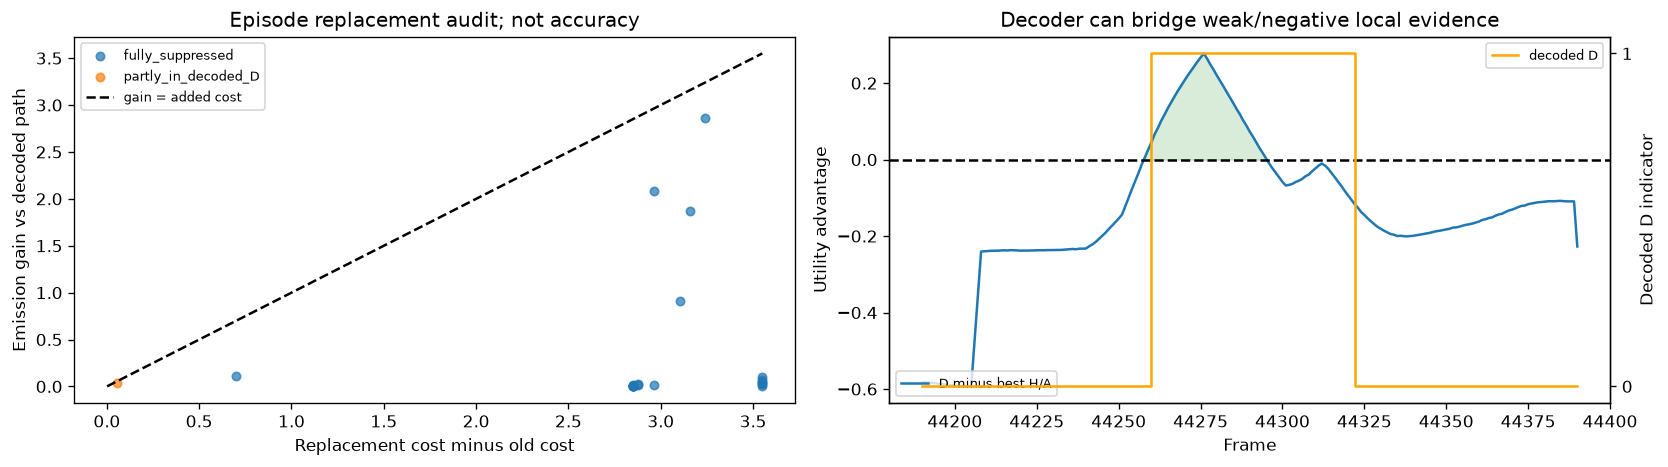

**Cara membaca:** titik di bawah garis gain=added cost tidak menguntungkan jika episode itu saja diganti menjadi D. Overlap decoded D bukan validasi kebenaran. Decoder dapat menjembatani bagian utility negatif, sehingga persistence tambahan belum otomatis diperlukan. Audit ini hanya satu alternatif lokal dan tidak membandingkan semua jalur.

In [8]:
fig,axes=plt.subplots(1,2,figsize=(14,4))
for outcome,g in d1_episodes.groupby('outcome'):
    axes[0].scatter(g.replacement_transition_cost-g.old_transition_cost,g.emission_gain,label=outcome,s=25,alpha=.7)
if len(d1_episodes):
    values=np.r_[d1_episodes.replacement_transition_cost-d1_episodes.old_transition_cost,d1_episodes.emission_gain]
    low,high=float(values.min()),float(values.max())
    axes[0].plot([low,high],[low,high],color='black',ls='--',label='gain = added cost')
axes[0].set(xlabel='Replacement cost minus old cost',ylabel='Emission gain vs decoded path',title='Episode replacement audit; not accuracy')
axes[0].legend(fontsize=8)
d1_decoded_segments=segments_for_labels(d1.decoded_label.to_numpy(),natural_half,d1_fps)
d1_decoded_dead=d1_decoded_segments.loc[d1_decoded_segments.label.eq('D')]
if len(d1_decoded_dead):
    r=d1_decoded_dead.loc[d1_decoded_dead.duration_s.idxmax()]
    center=(int(r.start_frame)+int(r.end_frame))//2
else:
    center=int(d1.loc[d1_natural,'dead_advantage'].idxmax())
half=int(d1.iloc[center].half)
z=d1.loc[d1.frame.between(center-100,center+100)&d1.half.eq(half)&~d1.forced_d]
axes[1].plot(z.frame,z.dead_advantage,label='D minus best H/A')
axes[1].axhline(0,color='black',ls='--')
axes[1].fill_between(z.frame,0,z.dead_advantage,where=z.dead_advantage>0,color='green',alpha=.15)
other=axes[1].twinx();other.step(z.frame,z.decoded_label.eq('D').astype(int),where='post',color='orange',label='decoded D')
other.set(ylim=(-.05,1.05),yticks=[0,1],ylabel='Decoded D indicator')
axes[1].set(title='Decoder can bridge weak/negative local evidence',xlabel='Frame',ylabel='Utility advantage')
axes[1].legend(loc='lower left',fontsize=8);other.legend(loc='upper right',fontsize=8)
plt.tight_layout();plt.show()
display(Markdown('**Cara membaca:** titik di bawah garis gain=added cost tidak menguntungkan jika episode itu saja diganti menjadi D. '
    'Overlap decoded D bukan validasi kebenaran. Decoder dapat menjembatani bagian utility negatif, sehingga persistence tambahan belum otomatis diperlukan. '
    'Audit ini hanya satu alternatif lokal dan tidak membandingkan semua jalur.'))


**Interpretasi dan arah keputusan - episode D**

| Jika terlihat | Makna yang didukung | Arah berikutnya |
|---|---|---|
| Episode positif ditolak dan net gain negatif | Objective tidak mendukung penggantian lokal itu | Periksa kekuatan/durasi evidence sebelum mengubah penalti |
| Ada net gain positif | Ada ketidaksesuaian yang perlu ditelusuri | Periksa hint, indeks, versi kode, dan postprocessing; jangan langsung menyebut bug |
| Decoded D menjembatani utility negatif | Decoder sudah memberi persistensi | Hindari menambah memory D tanpa bukti kebutuhan |
| Banyak episode positif hanya beberapa frame | Bukti sangat lokal | Pertimbangkan penggabungan bukti positif yang andal, bukan memperpanjang label secara buta |


## 8. Pemeriksaan D1 - cakupan bukti dan konteks set piece

**Pertanyaan:** Apakah evidence D hampir hanya muncul ketika bola di luar lapangan atau di pulsa anchor? Bagaimana kondisi skor pada konteks set piece lainnya?

Kategori di bawah adalah kondisi sinyal yang sudah disimpan, bukan anotasi stoppage. `outside_usable` memerlukan out-of-pitch hint positif dan bobot observasi bola positif. Total bonus live/dead di atas prior tidak memisahkan kontribusi individual komponennya; perincian itu perlu instrumentasi src pada tahap pengembangan berikutnya.

Tabel event memakai interval [start,end). Bagian forced/ungraded dilaporkan dan hanya interval sepenuhnya alami dipakai pada ringkasan per jenis. Tidak semua interval set piece adalah dead ball.


,half,support_regime,frames,positive_D_frames,decoded_D_frames,median_live,median_dead,median_live_bonus,median_dead_bonus,observed_fraction,exposure_s,positive_D_fraction
0,1,anchor_and_outside,114,70,41,0.716581,0.7536,0.166581,0.5036,1.000000,4.56,0.614035
1,1,anchor_only,2483,23,0,0.608871,0.3524,0.058871,0.1024,0.511075,99.32,0.009263
2,1,neither,76055,0,0,0.671381,0.2500,0.121381,0.0000,0.591217,3042.20,0.000000
3,1,outside_only,815,7,21,0.764508,0.6000,0.214508,0.3500,1.000000,32.60,0.008589
4,2,anchor_and_outside,78,44,0,0.749046,0.7408,0.199046,0.4908,1.000000,3.12,0.564103
5,2,anchor_only,2997,5,0,0.615549,0.3564,0.065549,0.1064,0.482482,119.88,0.001668
6,2,neither,72116,0,0,0.679911,0.2500,0.129911,0.0000,0.580897,2884.64,0.000000
7,2,outside_only,1265,20,0,0.725198,0.6000,0.175198,0.3500,1.000000,50.60,0.015810


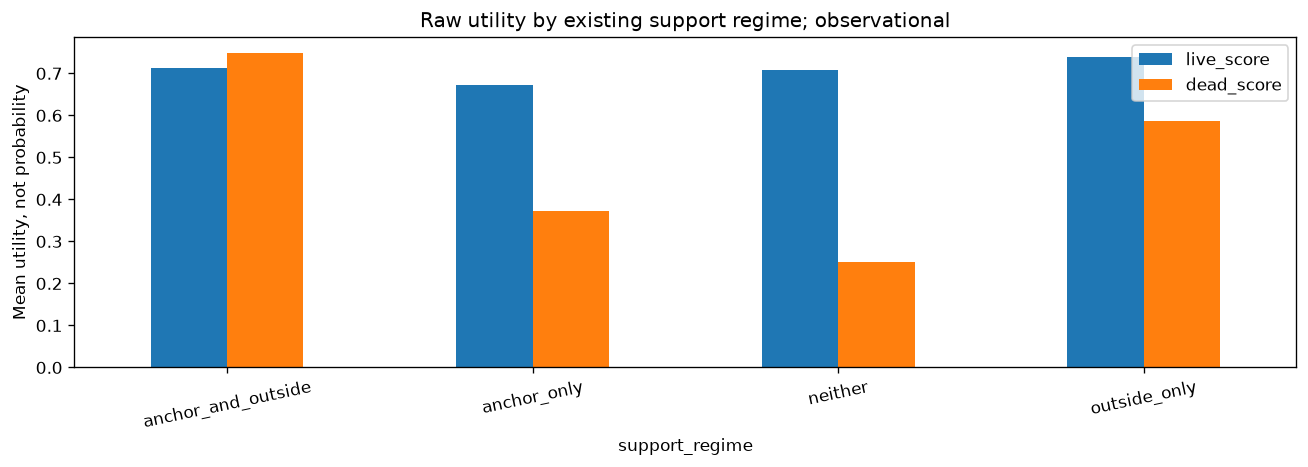

,event_row,type,side,start_frame,end_frame_exclusive,interval_frames,natural_frames,forced_frames,ungraded_frames,complete_natural,observed_fraction,median_live,median_dead,dead_bonus_fraction,positive_D_frames,max_dead_advantage,longest_positive_run_s,decoded_D_frames
0,0,Kick Off (Start),?,11097,11222,125,37,0,88,False,0.945946,0.805514,0.2836,0.648649,0,-0.300000,0.00,0
1,1,Kick Off (After Goal),?,49631,49756,125,125,0,0,True,0.344000,0.564743,0.2500,0.392000,1,0.007133,0.04,0
2,2,Kick Off (After Goal),?,62012,62137,125,125,0,0,True,0.000000,0.582896,0.2500,0.392000,0,-0.014290,0.00,0
3,3,Kick Off (After Goal),?,75457,75582,125,125,0,0,True,0.400000,0.579051,0.2500,0.392000,0,-0.008001,0.00,0
4,4,Kick Off (Start),?,113660,113785,125,43,82,0,False,1.000000,0.815723,0.2668,0.558140,0,-0.435607,0.00,0
5,5,Kick Off (After Goal),?,163000,163125,125,125,0,0,True,0.336000,0.563571,0.2500,0.392000,1,0.001200,0.04,0
6,6,Corner Kick,H,130321,131196,875,875,0,0,True,0.222857,0.607453,0.2500,0.056000,1,0.011382,0.04,0
7,7,Corner Kick,A,42614,43489,875,875,0,0,True,0.689143,0.781389,0.2500,0.056000,0,-0.013863,0.00,0
8,8,Corner Kick,A,36939,37814,875,875,0,0,True,0.870857,0.744225,0.2500,0.122286,3,0.018842,0.12,0
9,9,Corner Kick,A,136426,137301,875,875,0,0,True,0.656000,0.697091,0.2500,0.056000,0,-0.016524,0.00,0


,intervals,forced_frames,ungraded_frames
complete_natural,,,
False,2,82,88
True,57,0,0


,type,intervals,intervals_with_positive_D,intervals_with_decoded_D,median_observed_fraction,median_live,median_dead,median_dead_bonus_fraction,max_positive_run_s
0,Corner Kick,12,4,0,0.641143,0.701070,0.25,0.056000,0.12
1,Free Kick,5,3,0,0.665143,0.673303,0.25,0.062857,0.24
2,Goal Kick,10,2,0,0.804571,0.715642,0.25,0.108571,0.08
3,Kick Off (After Goal),4,2,0,0.340000,0.571897,0.25,0.392000,0.04
4,Throw-in,26,8,1,0.801143,0.762557,0.25,0.112000,0.80


**Batas simpulan:** overlap event bukan jumlah stoppage benar. Dominasi satu support regime dapat mengikuti definisi modul D itu sendiri, bukan membuktikan bahwa regime lain seharusnya D. Jika set-piece context hampir tidak menaikkan evidence D, perubahan berikutnya perlu memperjelas bukti positif dan semantik waktunya, bukan menyalin interval tag.

In [9]:
d1_anchor=d1.stoppage_anchor.gt(0)|d1.restart_anchor.gt(0)
d1_outside=d1.out_of_pitch_hint.gt(0)&d1.ball_weight.gt(0)
d1['support_regime']=np.select([d1_anchor&d1_outside,d1_anchor,d1_outside],
    ['anchor_and_outside','anchor_only','outside_only'],default='neither')
d1_support=d1.loc[d1_natural].groupby(['half','support_regime'],observed=True).agg(
    frames=('frame','size'),positive_D_frames=('positive_D','sum'),
    decoded_D_frames=('decoded_label',lambda s:int(s.eq('D').sum())),
    median_live=('live_score','median'),median_dead=('dead_score','median'),
    median_live_bonus=('live_dynamic_bonus','median'),median_dead_bonus=('dead_dynamic_bonus','median'),
    observed_fraction=('ball_observed','mean')).reset_index()
d1_support['exposure_s']=d1_support.frames/d1_fps
d1_support['positive_D_fraction']=d1_support.positive_D_frames/d1_support.frames
display(d1_support)
fig,ax=plt.subplots(figsize=(11,4))
d1.loc[d1_natural].groupby('support_regime')[['live_score','dead_score']].mean().plot.bar(ax=ax,rot=12)
ax.set(title='Raw utility by existing support regime; observational',ylabel='Mean utility, not probability')
plt.tight_layout();plt.show()

d1_events=read_table(f1_dir,'features/initial/events.csv')
d1_setpieces=d1_events.loc[d1_events.code_clean.eq('SET PIECES')].reset_index(drop=True)
d1_event_rows=[]
for event_row,r in enumerate(d1_setpieces.itertuples(index=False)):
    start,end=int(r.start_frame),int(r.end_frame)
    full=d1.iloc[start:end];g=full.loc[d1_natural.iloc[start:end]]
    positive_runs=list(_runs((d1_natural.iloc[start:end]&full.dead_advantage.gt(1e-9)).to_numpy(bool)))
    d1_event_rows.append({'event_row':event_row,'type':str(getattr(r,'Type','unknown')),'side':r.side,
        'start_frame':start,'end_frame_exclusive':end,'interval_frames':len(full),'natural_frames':len(g),
        'forced_frames':int(full.forced_d.sum()),'ungraded_frames':int((~full.graded).sum()),
        'complete_natural':len(g)==len(full) and len(g)>0,
        'observed_fraction':g.ball_observed.mean(),'median_live':g.live_score.median(),'median_dead':g.dead_score.median(),
        'dead_bonus_fraction':g.dead_dynamic_bonus.gt(1e-9).mean(),'positive_D_frames':int(g.positive_D.sum()),
        'max_dead_advantage':g.dead_advantage.max(),
        'longest_positive_run_s':max((b-a+1 for a,b in positive_runs),default=0)/d1_fps,
        'decoded_D_frames':int(g.decoded_label.eq('D').sum())})
d1_event_audit=pd.DataFrame(d1_event_rows)
display(d1_event_audit)
display(d1_event_audit.groupby('complete_natural').agg(intervals=('event_row','size'),
    forced_frames=('forced_frames','sum'),ungraded_frames=('ungraded_frames','sum')))
d1_event_summary=d1_event_audit.loc[d1_event_audit.complete_natural].groupby('type',dropna=False).agg(
    intervals=('event_row','size'),intervals_with_positive_D=('positive_D_frames',lambda s:int(s.gt(0).sum())),
    intervals_with_decoded_D=('decoded_D_frames',lambda s:int(s.gt(0).sum())),
    median_observed_fraction=('observed_fraction','median'),median_live=('median_live','median'),
    median_dead=('median_dead','median'),median_dead_bonus_fraction=('dead_bonus_fraction','median'),
    max_positive_run_s=('longest_positive_run_s','max')).reset_index()
display(d1_event_summary)
display(Markdown('**Batas simpulan:** overlap event bukan jumlah stoppage benar. '
    'Dominasi satu support regime dapat mengikuti definisi modul D itu sendiri, bukan membuktikan bahwa regime lain seharusnya D. '
    'Jika set-piece context hampir tidak menaikkan evidence D, perubahan berikutnya perlu memperjelas bukti positif dan semantik waktunya, bukan menyalin interval tag.'))


## 9. Pemeriksaan D1 - bagaimana model kembali Live?

**Pertanyaan:** Apakah kembalinya Live terkait kenaikan bukti gerak, hilangnya bukti D, atau keduanya?

Audit pertama memeriksa exit decoded D alami (bukan exit forced-D). Bandingkan satu detik sebelum/sesudah exit. Audit kedua memakai jendela dua detik di sekitar set_piece_end otomatis, dengan jendela yang menyentuh forced/ungraded/batas babak dikeluarkan. Batas tag bukan restart yang terverifikasi.

Live dynamic bonus adalah total tambahan di atas prior. Ketika ball_motion_reliable=False, modul sekarang tidak memberi bonus gerak bola, tetapi asosiasi agregat dengan player motion tetap bukan validasi kondisi Live. Jumlah exit D alami yang kecil membatasi generalisasi.


Natural decoded D exits: 1
Eligible set_piece_end windows: 57 excluded: 2


,half,frame,before_frames,after_frames,live_before,live_after,delta_live,dead_before,dead_after,delta_dead,live_minus_dead_margin_change,ball_motion_reliable_before,ball_motion_reliable_after,player_motion_before,player_motion_after,outside_hint_before,outside_hint_after,restart_anchor_at_exit
0,1,44322,25,25,0.653855,0.779633,0.125778,0.60512,0.6,-0.00512,0.130898,1.0,1.0,1.317094,1.2497,1.0,1.0,0.0


frames  observed_fraction  median_live  median_live_bonus  median_dead  positive_D_frames
ball_motion_reliable has_player_motion                                                                                           
False                False                2054           0.000487     0.550000           0.000000         0.25                  0
                     True                62220           0.003118     0.589322           0.039322         0.25                 11
True                 False                 183           1.000000     0.716324           0.166324         0.60                  7
                     True                91466           1.000000     0.818506           0.268506         0.25                151

,frame,half,before_frames,after_frames,delta_live,delta_dead,ball_motion_before,ball_motion_after,player_motion_before,player_motion_after,decoded_D_before,decoded_D_after
count,57.000000,57.00000,57.0,57.0,57.000000,57.000000,57.000000,57.000000,57.000000,57.000000,57.0,57.0
mean,107001.017544,1.54386,50.0,50.0,0.009230,-0.003204,0.691579,0.721053,1.649702,1.681317,0.0,0.0
std,58144.071618,0.50250,0.0,0.0,0.075401,0.027279,0.445581,0.429359,0.848654,0.871157,0.0,0.0
min,18408.000000,1.00000,50.0,50.0,-0.145918,-0.165200,0.000000,0.000000,0.480840,0.417292,0.0,0.0
25%,49756.000000,1.00000,50.0,50.0,-0.028525,0.002800,0.000000,0.520000,1.089140,1.125436,0.0,0.0
50%,122096.000000,2.00000,50.0,50.0,-0.002542,0.002800,1.000000,1.000000,1.422994,1.394870,0.0,0.0
75%,157725.000000,2.00000,50.0,50.0,0.047170,0.002800,1.000000,1.000000,1.989381,1.994540,0.0,0.0
max,189307.000000,2.00000,50.0,50.0,0.196446,0.019696,1.000000,1.000000,4.520611,5.137344,0.0,0.0


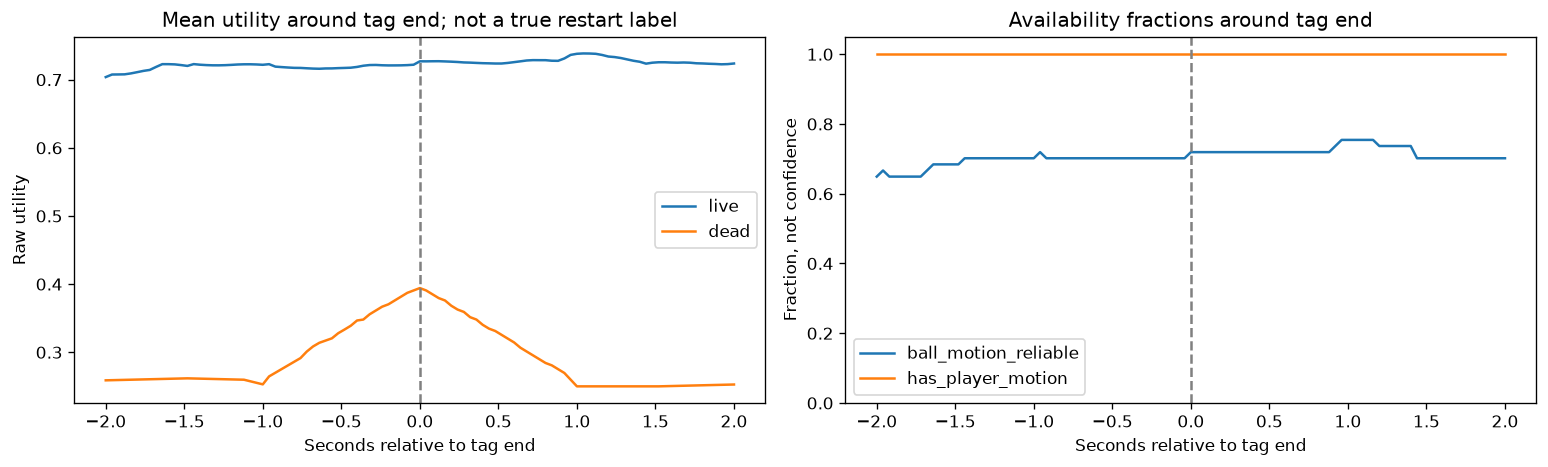

In [10]:
d1_prev_natural=d1_natural.shift(fill_value=False)
d1_exit_mask=(d1.decoded_label.shift().eq('D')&d1.decoded_label.isin(['H','A'])
    &d1.half.eq(d1.half.shift())&d1_natural&d1_prev_natural)
d1_exit_rows=[]
for t in d1.loc[d1_exit_mask,'frame'].astype(int):
    half=int(d1.iloc[t].half);before=d1.iloc[max(0,t-int(d1_fps)):t]
    after=d1.iloc[t:min(len(d1),t+int(d1_fps))]
    before=before.loc[before.half.eq(half)&before.graded&~before.forced_d]
    after=after.loc[after.half.eq(half)&after.graded&~after.forced_d]
    if not len(before) or not len(after):continue
    dl=float(after.live_score.mean()-before.live_score.mean())
    dd=float(after.dead_score.mean()-before.dead_score.mean())
    d1_exit_rows.append({'half':half,'frame':t,'before_frames':len(before),'after_frames':len(after),
        'live_before':before.live_score.mean(),'live_after':after.live_score.mean(),'delta_live':dl,
        'dead_before':before.dead_score.mean(),'dead_after':after.dead_score.mean(),'delta_dead':dd,
        'live_minus_dead_margin_change':dl-dd,
        'ball_motion_reliable_before':before.ball_motion_reliable.mean(),'ball_motion_reliable_after':after.ball_motion_reliable.mean(),
        'player_motion_before':before.player_motion_evidence.mean(),'player_motion_after':after.player_motion_evidence.mean(),
        'outside_hint_before':before.out_of_pitch_hint.mean(),'outside_hint_after':after.out_of_pitch_hint.mean(),
        'restart_anchor_at_exit':float(d1.iloc[t].restart_anchor)})
d1_exits=pd.DataFrame(d1_exit_rows)
print('Natural decoded D exits:',len(d1_exits))
display(d1_exits)
display(d1.loc[d1_natural].groupby(['ball_motion_reliable','has_player_motion'],observed=True).agg(
    frames=('frame','size'),observed_fraction=('ball_observed','mean'),median_live=('live_score','median'),
    median_live_bonus=('live_dynamic_bonus','median'),median_dead=('dead_score','median'),
    positive_D_frames=('positive_D','sum')))

d1_candidates=read_table(f1_dir,f'core/{f1_pass}/events/candidates.csv')
d1_restart_rows=[];d1_restart_profiles=[];d1_restart_exclusions=[]
radius=int(2*d1_fps)
for r in d1_candidates.loc[d1_candidates.event.eq('set_piece_end')].itertuples(index=False):
    t=int(r.frame);lo,hi=t-radius,t+radius
    if lo<0 or hi>=len(d1):
        d1_restart_exclusions.append('outside_video');continue
    window=d1.iloc[lo:hi+1]
    if not window.graded.all() or not window.half.eq(window.half.iloc[0]).all():
        d1_restart_exclusions.append('cross_half_or_ungraded');continue
    if window.forced_d.any():
        d1_restart_exclusions.append('touches_forced_D');continue
    before=window.loc[window.frame<t];after=window.loc[window.frame.ge(t)&window.frame.lt(t+radius)]
    assert len(before)==len(after)==radius
    d1_restart_rows.append({'frame':t,'half':int(window.half.iloc[0]),'before_frames':len(before),'after_frames':len(after),
        'delta_live':after.live_score.mean()-before.live_score.mean(),
        'delta_dead':after.dead_score.mean()-before.dead_score.mean(),
        'ball_motion_before':before.ball_motion_reliable.mean(),'ball_motion_after':after.ball_motion_reliable.mean(),
        'player_motion_before':before.player_motion_evidence.mean(),'player_motion_after':after.player_motion_evidence.mean(),
        'decoded_D_before':before.decoded_label.eq('D').mean(),'decoded_D_after':after.decoded_label.eq('D').mean()})
    for row in window.itertuples(index=False):
        d1_restart_profiles.append({'offset_s':(int(row.frame)-t)/d1_fps,'live':row.live_score,'dead':row.dead_score,
            'ball_motion_reliable':float(row.ball_motion_reliable),'has_player_motion':float(row.has_player_motion)})
d1_restarts=pd.DataFrame(d1_restart_rows)
print('Eligible set_piece_end windows:',len(d1_restarts),'excluded:',len(d1_restart_exclusions))
display(d1_restarts.describe())
d1_restart_profile=pd.DataFrame(d1_restart_profiles).groupby('offset_s').mean(numeric_only=True)
fig,axes=plt.subplots(1,2,figsize=(13,4))
d1_restart_profile[['live','dead']].plot(ax=axes[0],title='Mean utility around tag end; not a true restart label')
d1_restart_profile[['ball_motion_reliable','has_player_motion']].plot(ax=axes[1],ylim=(0,1.05),title='Availability fractions around tag end')
for ax in axes:ax.axvline(0,color='gray',ls='--');ax.set_xlabel('Seconds relative to tag end')
axes[0].set_ylabel('Raw utility');axes[1].set_ylabel('Fraction, not confidence')
plt.tight_layout();plt.show()


## 10. Simpulan pemeriksaan D1 dan keputusan pengembangan

| Amati | Jika hasilnya seperti ini | Arah keputusan |
|---|---|---|
| Episode D positif ditolak | Net gain negatif | Decoder mengikuti objective; cari evidence yang lebih informatif, bukan langsung menurunkan cost |
| Dukungan D sudah dijembatani decoder | Interval decoded lebih panjang dari run positif | Persistence label tambahan berisiko menduplikasi efek temporal |
| D hanya kompetitif pada kombinasi sinyal tertentu | Cakupan bukti sempit | Pertimbangkan evidence stoppage positif untuk kondisi lain, dengan skenario sintetis |
| Set-piece context tidak memberi D yang kompetitif | Belum membuktikan intervalnya dead | Audit semantik event dan komponen evidence di src; jangan menjadikan seluruh tag sebagai D |
| Live kembali terutama karena D turun | Pelepasan bukti stoppage berperan | Jangan menyimpulkan motion bonus sebagai penyebab utama |
| Live kembali karena kenaikan motion | Motion bisa membantu atau menyesatkan saat Dead | Rancang ablation/synthetic player-motion-during-stoppage sebelum ubah bobot |
| Exit alami hanya sedikit | Bukti generalisasi lemah | Pakai skenario sintetis dan konteks kandidat lain, bukan parameter khusus frame |

**Calon D1 setelah diskusi:** kombinasi bukti positif dan andal, dengan dukungan temporal terbatas jika dibutuhkan, serta pelepasan oleh bukti restart/Live. Bukan missing->D, diam->D, seluruh set piece->D, atau mempertahankan D sampai tag berikutnya.

**Tahap berikutnya sebelum mengubah rumus:** bila perlu atribusi individual, tambahkan komponen return diagnostik live/dead di src dengan submission yang tetap identik. Baru pilih satu intervensi D1 dan run terpisah. Pemeriksaan ini sendiri tidak mengubah evidence, utility, decoder atau label.


In [11]:
d1_suppressed=d1_episodes.loc[d1_episodes.outcome.eq('fully_suppressed')]
d1_max_positive=d1_episodes.duration_s.max() if len(d1_episodes) else 0.
d1_max_decoded=d1_decoded_dead.duration_s.max() if len(d1_decoded_dead) else 0.
display(Markdown(f"**Temuan episode:** {len(d1_episodes):,} episode utility D positif, total {int(d1.positive_D.sum()):,} frame. "
    f"{len(d1_suppressed):,} episode sepenuhnya tidak dipilih sebagai decoded D; "
    f"{int(d1_suppressed.net_gain.gt(1e-7).sum()):,} di antaranya memiliki keuntungan penggantian lokal positif. "
    f"Run positif terpanjang {d1_max_positive:.2f} detik; decoded D alami terpanjang {d1_max_decoded:.2f} detik. "
    "Perbedaan durasi ini menunjukkan perlunya memisahkan bukti lokal dari persistensi jalur temporal."))
display(Markdown(f"**Batas dan keputusan:** ada {len(d1_exits):,} exit decoded D alami untuk dianalisis. "
    "Ini belum cukup untuk menyimpulkan mekanisme restart secara umum. "
    "Gunakan tabel cohort, support regime, dan objective audit untuk memilih kebutuhan D1: pembentukan bukti, durasi dukungan, atau pelepasan state. "
    "Belum ada perubahan model atau klaim kenaikan akurasi."))


**Temuan episode:** 21 episode utility D positif, total 169 frame. 20 episode sepenuhnya tidak dipilih sebagai decoded D; 0 di antaranya memiliki keuntungan penggantian lokal positif. Run positif terpanjang 1.52 detik; decoded D alami terpanjang 2.48 detik. Perbedaan durasi ini menunjukkan perlunya memisahkan bukti lokal dari persistensi jalur temporal.

**Batas dan keputusan:** ada 1 exit decoded D alami untuk dianalisis. Ini belum cukup untuk menyimpulkan mekanisme restart secara umum. Gunakan tabel cohort, support regime, dan objective audit untuk memilih kebutuhan D1: pembentukan bukti, durasi dukungan, atau pelepasan state. Belum ada perubahan model atau klaim kenaikan akurasi.

### Ringkasan interpretasi D1 untuk run `20261115_232213_442294_bf05582d`

Ringkasan ini mencatat hasil run tersebut, bukan kesimpulan otomatis untuk run lain.

1. **Biaya dan bukti lokal konsisten dengan decoded path.** Ada 21 episode positif (169 frame). Sebanyak 20 episode, total 131 frame, sepenuhnya tidak dipilih sebagai decoded D. Seluruhnya memiliki net gain penggantian lokal negatif; median -2.8485 dan maksimum -0.3829. Audit lokal cocok dengan selisih objective seluruh jalur pada tiga episode yang dipilih otomatis. Tidak ada indikasi bahwa decoder mengabaikan alternatif lokal yang lebih menguntungkan pada audit ini.
2. **Persistensi sudah terjadi.** Run utility D positif terpanjang 1.52 detik, sedangkan decoded D alami terpanjang 2.48 detik. Setelah refinement, interval final menjadi 2.52 detik. Jadi kebutuhan memperpanjang evidence/label tidak boleh diasumsikan hanya karena raw-positive runs pendek.
3. **Cakupan evidence D masih sempit.** Dari 169 frame positif, 114 berada pada anchor+outside, 28 pada anchor saja, dan 27 pada outside saja. Tidak ada pada neither. Ini juga mengikuti definisi sumber bukti yang tersedia, sehingga bukan pembuktian bahwa frame lain seharusnya D.
4. **Set piece adalah konteks, bukan target label.** Pada 57 interval yang sepenuhnya alami, median dead_score per kelompok jenis tetap 0.25. Hanya satu interval konteks memiliki decoded D. Ini menyoroti betapa lokalnya bonus D, tetapi tidak berarti seluruh interval tag harus diberi D; banyak interval tag merupakan jendela fase yang mencakup permainan Live.
5. **Satu contoh pelepasan D berkaitan terutama dengan kenaikan raw Live.** Pada satu exit alami, mean live_score naik 0.1258 sementara mean dead_score turun 0.0051. Mean player_motion turun dari 1.3171 ke 1.2497; outside hint rata-rata tetap 1.0 dan restart anchor pada exit bernilai 0. Tidak tepat menyimpulkan bahwa outside evidence menghilang atau player motion naik. Kontribusi bonus individual belum tersimpan, dan satu contoh belum menjelaskan restart secara umum.
6. **Profil set_piece_end belum memvalidasi restart.** Ada 57 jendela yang lolos filter; decoded D di jendela sebelum/sesudahnya selalu nol. Profil ini menjelaskan sinyal di sekitar batas tag, bukan evaluasi terhadap 57 restart yang diketahui benar.

**Arah keputusan:** prioritaskan perincian sumber bukti live/dead dan rancangan bukti stoppage positif yang andal, beserta mekanisme pelepasannya. Jangan dulu menurunkan transition cost, memperpanjang D sampai tag berikutnya, atau menganggap missing/diam sebagai D. Bila dibutuhkan atribusi per-komponen, expose return diagnostiknya di src dan verifikasi submission tetap identik sebelum menguji satu perubahan D1.

**Status:** hanya pemeriksaan diagnostik; model, config, submission, dan artefak F1 tidak diubah. Tidak ada pengukuran akurasi atau klaim peningkatan spellF1.


## 11. Pengembangan D1 - evidence persiapan kontekstual

**Hipotesis:** setelah F1, evidence D masih sangat lokal. Konjungsi konteks set piece, bola lambat yang teramati/andal, dan rerata gerak rendah dengan motion kedua tim yang valid dapat memberi dukungan positif tambahan tanpa menyamakan missing ball atau bola diam dengan Dead.

**Satu mekanisme baru:** `live_dead.context_stoppage`. Seluruh prior/bobot lama, F1 max-centering, control, decoder, boundary dan video tetap sama. Perincian skor kini disimpan di `core/<pass>/live_dead/components.csv` dan `metadata.json`.

| Pengaturan awal | Nilai | Alasan / batas |
|---|---|---|
| Trailing window | 10 frame = 0.4 detik pada 25 FPS | Memerlukan sejarah penuh dalam babak; bukan minimum durasi label D |
| Minimum support | 0.8 | Minimal 80% cue dalam jendela, dan cue saat ini tetap wajib |
| Ball speed maksimum | 0.6 m/s | Menggunakan ambang stationary yang sudah ada |
| Player motion maksimum | 1.5 m/s | Hipotesis awal batas rerata gerak kedua tim; keduanya harus memiliki motion valid |
| Player quality minimum | 0.65 | Gate cakupan, bukan confidence 65% |
| Weight | 0.55 | Support >=0.8 memberi tambahan >=0.44 ketika ball weight=1; tidak dikalibrasi sebagai probabilitas |

Cue harus terjadi bersamaan. Kontribusi baru langsung nol jika bola hilang, motion tidak andal, gerak meningkat, kualitas tidak cukup, atau konteks berakhir. History tidak melintasi babak. Tidak ada latch sampai tag berikutnya; decoder tetap menangani kontinuitas state.

**Risiko:** permainan Live yang tenang di dalam interval tag otomatis yang lebar dapat memenuhi proxy ini. Observasi identik tidak dapat dijanjikan memiliki label berbeda. Seluruh nilai adalah hipotesis awal, bukan hasil tuning public GT atau anotasi pertandingan.


In [12]:
pd.set_option('display.max_columns', None)
D1_MODEL_CONFIG = ROOT/'config/d1.yaml'
D1_STORAGE_CONFIG = ROOT/'config/artifacts_d1.yaml'
d1exp_config=yaml.safe_load(D1_MODEL_CONFIG.read_text(encoding='utf-8-sig'))
d1exp_parent_config=read_json(f1_dir,'config/model.json')
d1exp_check=deepcopy(d1exp_config)
d1exp_context_cfg=d1exp_check['live_dead'].pop('context_stoppage')
assert d1exp_context_cfg['enabled'] is True
assert d1exp_check==d1exp_parent_config, 'D1 must only add context_stoppage to this F1 parent'
print('D1 parent:',f1_manifest['run_id'])
display(d1exp_context_cfg)
display(yaml.safe_load(D1_STORAGE_CONFIG.read_text(encoding='utf-8-sig')))


{'enabled': True, 'window_frames': 10, 'minimum_support_fraction': 0.8, 'stationary_ball_speed_mps': 0.6, 'max_player_motion_mps': 1.5, 'minimum_player_quality': 0.65, 'weight': 0.55}

{'root_dir': 'artifacts', 'submission_filename': 'baseline_d1.csv'}

D1 parent: 20261115_232213_442294_bf05582d


## 12. Jalankan D1 sebagai run terpisah

`RUN_D1=True` membuat run baru dari pipeline. Setelah run contoh selesai, False dapat dipakai untuk membuka hasil yang sudah disimpan. Config penyimpanan terpisah; F1 dan baseline v2 tidak ditimpa.


In [13]:
RUN_D1 = False
D1_RUN_ID = "20261116_001443_400968_322580b4"
if RUN_D1:
    d1exp_result=run_pipeline(d1exp_config,project_dir=ROOT,storage_config_path=D1_STORAGE_CONFIG,
        execution_metadata={'experiment':'D1_contextual_preparation','parent_run_id':f1_manifest['run_id'],
            'baseline_run_id':BASE_RUN_ID,'notebook':'notebooks/06_f1_fusion_experiment.ipynb',
            'model_config_source':str(D1_MODEL_CONFIG)})
    d1exp_dir=Path(d1exp_result.artifact_dir)
else:
    d1exp_candidates=[r for r in list_runs(project_dir=ROOT)
        if read_json(r['path'],'config/model.json').get('live_dead',{}).get('context_stoppage',{}).get('enabled',False)]
    if not d1exp_candidates:raise RuntimeError('Belum ada run D1 selesai; gunakan RUN_D1=True')
    d1exp_dir=(Path(d1exp_candidates[-1]['path']) if D1_RUN_ID is None else
        next(Path(r['path']) for r in d1exp_candidates if r['run_id']==D1_RUN_ID))
d1exp_manifest=read_json(d1exp_dir)
d1exp_pass=d1exp_manifest['final_core_pass']
assert d1exp_manifest['status']=='completed'
assert read_json(d1exp_dir,'config/model.json')==d1exp_config
print('D1 run:',d1exp_manifest['run_id'],'core:',d1exp_pass,'folder:',d1exp_dir)
display(read_json(d1exp_dir,'submission/validator/result.json'))


{'status': 'passed', 'message': 'OK    baseline_d1.csv\n      199319 rows, frame 0..199318\n\n      label counts\n        H    95706   48.0%\n        A    59298   29.8%\n        D     3853    1.9%\n        X    40462   20.3%\n\n      reports 1081 possessions of mean 5.7 s\n      (counted with each X as a gap; the scorer bridges abstentions inside a real\n       possession, so its count can be lower than this one)\n\nValid. Note this checks the format only -- it says nothing about whether the labels are right.\nScore it against the public ground truth with run_evaluation.py.'}

D1 run: 20261116_001443_400968_322580b4 core: initial folder: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\artifacts\20261116_001443_400968_322580b4


## 13. Verifikasi isolasi, komponen dan pelepasan cue

Keluaran fitur, quality, control, event, transition hint dan live_score harus identik dengan F1. `dead_without_context` adalah skor persis sebelum tambahan D1, sehingga harus sama dengan dead_score F1 tanpa menyalin rumus model ke notebook. Referensi ini bukan suku tambahan untuk dijumlahkan.

Utility H/A harus tetap sama. Di luar forced-D, perubahan utility D harus persis berasal dari komponen baru. Label D ketika cue tidak aktif masih mungkin karena evidence lama dan keputusan temporal; yang wajib nol saat cue dilepas adalah kontribusi baru, bukan paksa seluruh label menjadi Live.


In [14]:
d1exp_paths=[
    ('features/initial/frames.csv','features/initial/frames.csv'),
    ('features/initial/events.csv','features/initial/events.csv'),
    (f'core/{f1_pass}/quality/frames.csv',f'core/{d1exp_pass}/quality/frames.csv'),
    (f'core/{f1_pass}/control/frames.csv',f'core/{d1exp_pass}/control/frames.csv'),
    (f'core/{f1_pass}/control/scores.csv',f'core/{d1exp_pass}/control/scores.csv'),
    (f'core/{f1_pass}/events/frames.csv',f'core/{d1exp_pass}/events/frames.csv'),
    (f'core/{f1_pass}/fusion/transition_hint.csv',f'core/{d1exp_pass}/fusion/transition_hint.csv'),
    (f'core/{f1_pass}/live_dead/live_score.csv',f'core/{d1exp_pass}/live_dead/live_score.csv')]
d1exp_isolation=[]
for old_path,new_path in d1exp_paths:
    same_hash=f1_manifest['files'][old_path]['sha256']==d1exp_manifest['files'][new_path]['sha256']
    if not same_hash:
        pd.testing.assert_frame_equal(read_table(f1_dir,old_path),read_table(d1exp_dir,new_path),check_exact=True,check_dtype=False)
    d1exp_isolation.append({'artifact':new_path,'same_sha256':same_hash,'values_equivalent':True})
display(pd.DataFrame(d1exp_isolation))
d1exp_features=read_table(d1exp_dir,'features/initial/frames.csv')
d1exp_df=d1exp_features[['frame','half','graded','ball_ok','set_piece_tag','ball_speed2d_mps']].copy().sort_values('frame')
d1exp_df=join_frame(d1exp_df,read_table(f1_dir,f'core/{f1_pass}/fusion/state_log_scores.csv').rename(
    columns={'H':'f1_H','A':'f1_A','D':'f1_D'}))
d1exp_df=join_frame(d1exp_df,read_table(d1exp_dir,f'core/{d1exp_pass}/fusion/state_log_scores.csv').rename(
    columns={'H':'d1_H','A':'d1_A','D':'d1_D'}))
d1exp_df=join_frame(d1exp_df,read_table(f1_dir,f'core/{f1_pass}/live_dead/frames.csv')[['frame','live_score','dead_score']].rename(
    columns={'live_score':'f1_live','dead_score':'f1_raw_dead'}))
d1exp_df=join_frame(d1exp_df,read_table(d1exp_dir,f'core/{d1exp_pass}/live_dead/frames.csv')[['frame','live_score','dead_score','player_motion_evidence']].rename(
    columns={'live_score':'d1_live','dead_score':'d1_raw_dead','player_motion_evidence':'d1_player_motion'}))
d1exp_df=join_frame(d1exp_df,read_table(d1exp_dir,f'core/{d1exp_pass}/live_dead/components.csv'))
d1exp_df=join_frame(d1exp_df,read_table(d1exp_dir,f'core/{d1exp_pass}/quality/frames.csv')[
    ['frame','ball_observed','ball_motion_reliable','player_quality_weight']])
d1exp_df=join_frame(d1exp_df,read_table(d1exp_dir,f'core/{d1exp_pass}/fusion/control_components.csv')[['frame','forced_d']])
d1exp_df=join_frame(d1exp_df,read_table(f1_dir,'result/labels.csv').rename(columns={'label':'f1_final'}))
d1exp_df=join_frame(d1exp_df,read_table(d1exp_dir,'result/labels.csv').rename(columns={'label':'d1_final'}))
d1exp_df=join_frame(d1exp_df,read_table(d1exp_dir,f'core/{d1exp_pass}/decode/labels.csv').rename(columns={'label':'d1_decoded'}))
d1exp_natural=d1exp_df.graded&~d1exp_df.forced_d
d1exp_unforced=~d1exp_df.forced_d
np.testing.assert_array_equal(d1exp_df.d1_live,d1exp_df.f1_live)
np.testing.assert_array_equal(d1exp_df.dead_without_context,d1exp_df.f1_raw_dead)
np.testing.assert_array_equal(d1exp_df[['d1_H','d1_A']],d1exp_df[['f1_H','f1_A']])
np.testing.assert_allclose(d1exp_df.d1_raw_dead-d1exp_df.dead_without_context,d1exp_df.context_stoppage_dead,rtol=0,atol=1e-12)
np.testing.assert_allclose((d1exp_df.d1_D-d1exp_df.f1_D)[d1exp_unforced],
    (float(d1exp_config['fusion']['dead_weight'])*d1exp_df.context_stoppage_dead)[d1exp_unforced],rtol=0,atol=1e-12)
np.testing.assert_array_equal(d1exp_df.loc[d1exp_df.forced_d,['d1_H','d1_A','d1_D']],
                              d1exp_df.loc[d1exp_df.forced_d,['f1_H','f1_A','f1_D']])
d1exp_metadata=read_json(d1exp_dir,f'core/{d1exp_pass}/live_dead/metadata.json')
np.testing.assert_allclose(d1exp_df[d1exp_metadata['live_additive_columns']].sum(axis=1),d1exp_df.d1_live,rtol=0,atol=1e-12)
np.testing.assert_allclose(d1exp_df[d1exp_metadata['dead_additive_columns']].sum(axis=1),d1exp_df.d1_raw_dead,rtol=0,atol=1e-12)
active=d1exp_df.context_active
assert not d1exp_df.loc[~active,'context_stoppage_dead'].gt(0).any()
assert d1exp_df.loc[active,'ball_observed'].all() and d1exp_df.loc[active,'ball_motion_reliable'].all()
assert d1exp_df.loc[active,'both_team_motion_valid'].all() and d1exp_df.loc[active,'set_piece_tag'].all()
assert d1exp_df.loc[active,'ball_speed2d_mps'].le(d1exp_context_cfg['stationary_ball_speed_mps']).all()
assert d1exp_df.loc[active,'d1_player_motion'].le(d1exp_context_cfg['max_player_motion_mps']).all()
assert d1exp_df.loc[active,'player_quality_weight'].ge(d1exp_context_cfg['minimum_player_quality']).all()
assert d1exp_df.loc[active,'context_support_fraction'].ge(d1exp_context_cfg['minimum_support_fraction']).all()
print('PASS: instrumentation legacy identity, unchanged Live/H/A, exact D1 channel, quality gates and forced-D.')
display(d1exp_metadata)


,artifact,same_sha256,values_equivalent
0,features/initial/frames.csv,True,True
1,features/initial/events.csv,True,True
2,core/initial/quality/frames.csv,True,True
3,core/initial/control/frames.csv,True,True
4,core/initial/control/scores.csv,True,True
5,core/initial/events/frames.csv,True,True
6,core/initial/fusion/transition_hint.csv,True,True
7,core/initial/live_dead/live_score.csv,True,True


{'score_semantics': 'uncalibrated additive utilities; components are not probabilities', 'live_additive_columns': ['live_prior', 'ball_motion_live', 'player_motion_live'], 'dead_additive_columns': ['dead_prior', 'out_of_pitch_dead', 'stoppage_anchor_dead', 'restart_anchor_dead', 'stationary_near_anchor_dead', 'context_stoppage_dead'], 'nonadditive_reference': 'dead_without_context is the exact pre-D1 score, not an additional term', 'context_stoppage': {'enabled': True, 'window_frames': 10, 'minimum_support_fraction': 0.8, 'stationary_ball_speed_mps': 0.6, 'max_player_motion_mps': 1.5, 'minimum_player_quality': 0.65, 'weight': 0.55}, 'context_window': 'trailing, half-local; full history required', 'release': 'current cue must remain valid; no label latch or hold-until-tag-end', 'limitations': 'broad automatic event context can include stationary live play; D1 remains an experimental proxy'}

PASS: instrumentation legacy identity, unchanged Live/H/A, exact D1 channel, quality gates and forced-D.


## 14. Perbandingan hasil D1 vs F1

Tabel ini mengukur perubahan perilaku, bukan accuracy. Bertambahnya D dapat menambah atau mengurangi possession count melalui pemisahan interval. Jangan menganggap semua segmen D baru benar, dan jangan memilih model dari proporsi D atau jumlah spell yang tampak realistis.


In [15]:
d1exp_comparison=[]
for name,folder,pass_name,label in [('F1',f1_dir,f1_pass,'f1_final'),('D1',d1exp_dir,d1exp_pass,'d1_final')]:
    diag=read_json(folder,'submission/diagnostics.json')
    core=read_json(folder,f'diagnostics/{pass_name}/core/dead_score_summary.json')
    seg=read_table(folder,'diagnostics/final/prediction/segment_summary.csv')
    trans=read_table(folder,'diagnostics/final/prediction/transition_counts.csv')
    ha=seg.loc[seg.label.isin(['H','A'])]
    d1exp_comparison.append({'model':name,'natural_D_utility_wins':core['dead_wins_unforced'],
        'natural_D_frames':int(d1exp_df.loc[d1exp_natural,label].eq('D').sum()),'dead_segments_total':diag['dead_segments'],
        'HA_spells':diag['possession_spells'],'HA_short_lt_2s':int(ha.segments_lt_2s.sum()),
        'HA_transitions':int(trans.loc[trans['from'].isin(['H','A'])&trans['to'].isin(['H','A']),'count'].sum()),
        'median_HA_duration_s':diag['possession_median_s'],'total_transitions':diag['total_transitions']})
d1exp_comparison=pd.DataFrame(d1exp_comparison).set_index('model')
display(d1exp_comparison)
display(pd.crosstab(d1exp_df.loc[d1exp_natural,'f1_final'],d1exp_df.loc[d1exp_natural,'d1_final']))
d1exp_active=d1exp_df.loc[d1exp_natural&d1exp_df.context_active]
print('Natural active context frames:',len(d1exp_active),'seconds:',len(d1exp_active)/float(d1exp_config['fps']))
display(d1exp_active[['context_support_fraction','context_stoppage_dead','ball_speed2d_mps','d1_player_motion','player_quality_weight']].describe())


,natural_D_utility_wins,natural_D_frames,dead_segments_total,HA_spells,HA_short_lt_2s,HA_transitions,median_HA_duration_s,total_transitions
model,,,,,,,,
F1,169,63,2,1070,523,1067,2.04,1070
D1,1074,919,18,1081,528,1062,2.04,1097


d1_final,A,D,H
f1_final,,,
A,59298,416,0
D,0,63,0
H,0,440,95706


,context_support_fraction,context_stoppage_dead,ball_speed2d_mps,d1_player_motion,player_quality_weight
count,905.000000,905.000000,905.000000,905.000000,905.000000
mean,0.988398,0.543619,0.251580,0.957920,0.967690
std,0.042439,0.023342,0.151210,0.363607,0.024917
min,0.800000,0.440000,0.000000,0.208251,0.909091
25%,1.000000,0.550000,0.129000,0.684012,0.953463
50%,1.000000,0.550000,0.218753,1.038003,0.953463
75%,1.000000,0.550000,0.368258,1.275237,1.000000
max,1.000000,0.550000,0.599019,1.499279,1.000000


Natural active context frames: 905 seconds: 36.2


## 15. Konteks interval, komponen skor dan pelepasan

Periksa apakah bonus benar-benar dibatasi cue saat ini. Decoder masih boleh mempertahankan label D melewati sebagian frame tanpa bonus; ini berbeda dari latch dalam pembentukan evidence. Jendela contoh dipilih otomatis dari interval dengan dukungan D1, bukan anotasi manual.


,half,start_frame,end_frame,duration_s,context_active_fraction,ball_observed_fraction,set_piece_fraction,mean_context_bonus,F1_D_fraction,median_ball_speed,median_player_motion
0,1,30317,30340,0.96,1.000000,1.0,1.000000,0.543125,0.0,0.187499,1.128501
1,1,35487,35520,1.36,1.000000,1.0,1.000000,0.545147,0.0,0.321563,0.831526
2,1,39892,39910,0.76,1.000000,1.0,1.000000,0.541316,0.0,0.348790,0.717456
3,1,44259,44321,2.52,0.000000,1.0,0.730159,0.000000,1.0,1.105609,1.350825
4,1,46243,46268,1.04,1.000000,1.0,1.000000,0.543654,0.0,0.434877,0.272807
5,1,46346,46367,0.88,1.000000,1.0,1.000000,0.542500,0.0,0.205692,0.286654
6,1,53434,53520,3.48,1.000000,1.0,1.000000,0.548103,0.0,0.085983,1.362483
7,1,84846,84984,5.56,0.913669,1.0,0.992806,0.501331,0.0,0.135945,1.118676
8,2,121310,121375,2.64,1.000000,1.0,1.000000,0.547500,0.0,0.320587,0.878850
9,2,127536,127568,1.32,0.181818,1.0,1.000000,0.091667,0.0,0.599019,0.933525


,duration_s,context_active_fraction,F1_D_fraction
count,17.000000,17.000000,17.000000
mean,2.162353,0.858558,0.058824
std,1.447237,0.314918,0.242536
min,0.520000,0.000000,0.000000
25%,0.960000,1.000000,0.000000
50%,1.880000,1.000000,0.000000
75%,2.840000,1.000000,0.000000
max,5.560000,1.000000,1.000000


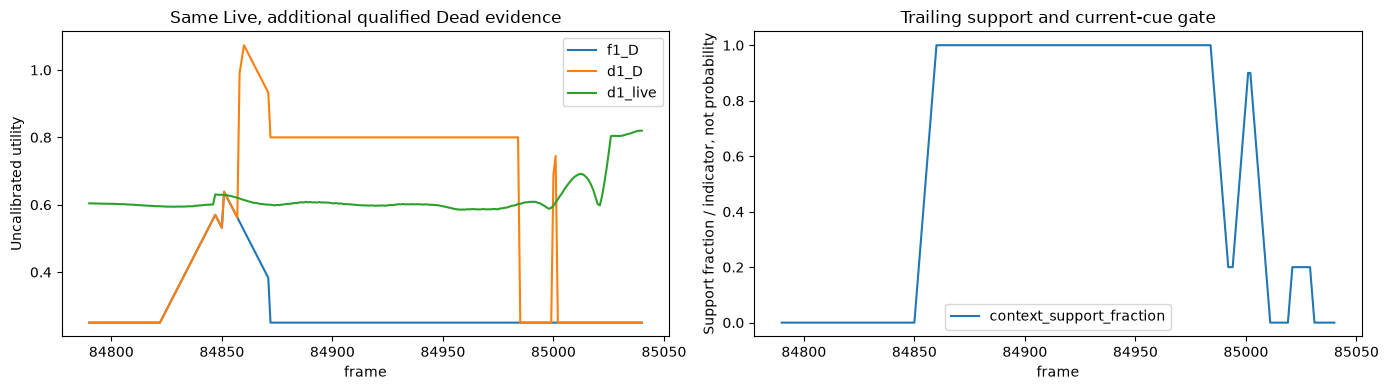

,frames,mean_dead_prior,mean_outside,mean_anchor,mean_context,mean_live,mean_dead
context_active,,,,,,,
False,155018,0.25,0.004911,0.002924,0.000000,0.707619,0.259307
True,905,0.25,0.005801,0.003069,0.543619,0.599386,0.819862


In [16]:
d1exp_half=np.where(d1exp_natural,d1exp_df.half.to_numpy(),0)
d1exp_segments=segments_for_labels(d1exp_df.d1_final.to_numpy(),d1exp_half,float(d1exp_config['fps']))
d1exp_dead=d1exp_segments.loc[d1exp_segments.label.eq('D')].copy()
d1exp_case_rows=[]
for r in d1exp_dead.itertuples(index=False):
    g=d1exp_df.iloc[int(r.start_frame):int(r.end_frame)+1]
    d1exp_case_rows.append({'half':r.half,'start_frame':r.start_frame,'end_frame':r.end_frame,'duration_s':r.duration_s,
        'context_active_fraction':g.context_active.mean(),'ball_observed_fraction':g.ball_observed.mean(),
        'set_piece_fraction':g.set_piece_tag.mean(),'mean_context_bonus':g.context_stoppage_dead.mean(),
        'F1_D_fraction':g.f1_final.eq('D').mean(),'median_ball_speed':g.ball_speed2d_mps.median(),
        'median_player_motion':g.d1_player_motion.median()})
d1exp_cases=pd.DataFrame(d1exp_case_rows,columns=['half','start_frame','end_frame','duration_s','context_active_fraction',
    'ball_observed_fraction','set_piece_fraction','mean_context_bonus','F1_D_fraction','median_ball_speed','median_player_motion'])
display(d1exp_cases.head(30))
if len(d1exp_cases):display(d1exp_cases[['duration_s','context_active_fraction','F1_D_fraction']].describe())
if len(d1exp_cases.loc[d1exp_cases.context_active_fraction.gt(0)]):
    chosen=d1exp_cases.loc[d1exp_cases.context_active_fraction.gt(0)].sort_values('duration_s',ascending=False).iloc[0]
    center=(int(chosen.start_frame)+int(chosen.end_frame))//2
elif len(d1exp_active):center=int(d1exp_active.context_stoppage_dead.idxmax())
else:center=int(d1exp_df.loc[d1exp_natural,'context_stoppage_dead'].idxmax())
half=int(d1exp_df.iloc[center].half)
z=d1exp_df.loc[d1exp_df.frame.between(center-125,center+125)&d1exp_df.half.eq(half)&~d1exp_df.forced_d]
fig,axes=plt.subplots(1,2,figsize=(14,4))
z.plot(x='frame',y=['f1_D','d1_D','d1_live'],ax=axes[0],title='Same Live, additional qualified Dead evidence')
z.assign(preparation_cue=z.preparation_cue.astype(float),context_active=z.context_active.astype(float)).plot(x='frame',y=['context_support_fraction','preparation_cue','context_active'],ax=axes[1],title='Trailing support and current-cue gate')
axes[0].set_ylabel('Uncalibrated utility');axes[1].set_ylabel('Support fraction / indicator, not probability')
plt.tight_layout();plt.show()
d1exp_group=d1exp_df.loc[d1exp_natural].groupby('context_active').agg(frames=('frame','size'),
    mean_dead_prior=('dead_prior','mean'),mean_outside=('out_of_pitch_dead','mean'),
    mean_anchor=('stoppage_anchor_dead','mean'),mean_context=('context_stoppage_dead','mean'),
    mean_live=('d1_live','mean'),mean_dead=('d1_raw_dead','mean'))
display(d1exp_group)


## 16. Interpretasi kandidat dan keputusan berikutnya

| Hasil | Interpretasi yang diizinkan | Keputusan |
|---|---|---|
| Komponen cocok dan Live/H/A tetap | Intervensi berhasil diisolasi | Bandingkan perilaku, bukan klaim skor meningkat |
| Cue aktif tetapi D tidak dipilih | Objective temporal masih menentukan | Periksa durasi/akumulasi sebelum mengubah cost |
| Tambahan D berasal dari cue gabungan | Mekanisme bekerja sesuai desain | Audit risiko quiet-live di broad tag; belum otomatis adopsi |
| Cue hilang tetapi label D bertahan sebentar | Bisa berasal dari decoder | Jangan menyebut contribution latch jika bonus sudah nol |
| Bonus tetap positif saat cue invalid | Implementasi tidak sesuai desain | Hentikan eksperimen dan perbaiki gate |
| D bertambah, H/A short spell berubah | Perubahan segmentasi bersama | Pisahkan efek stoppage dari perbaikan acquisition |
| Risiko live tenang tidak dapat dibedakan | Informasi observasi belum cukup | Cari evidence independen/validasi pertandingan lain; jangan memaksa threshold dari GT publik |

**Status D1:** kandidat heuristik berbasis kombinasi observasi, bukan detector stoppage yang telah tervalidasi. Seluruh parameter baru masih hipotesis. Model default tetap legacy bila context_stoppage tidak diaktifkan.


In [17]:
d1exp_new_frames=int(d1exp_comparison.loc['D1','natural_D_frames'])
d1exp_parent_frames=int(d1exp_comparison.loc['F1','natural_D_frames'])
display(Markdown(f"**Hasil D1:** bonus konteks aktif pada {len(d1exp_active):,} frame alami; "
    f"label D alami berubah dari {d1exp_parent_frames:,} menjadi {d1exp_new_frames:,} frame. "
    f"Jumlah interval D alami kandidat = {len(d1exp_dead):,}. "
    "Live/H/A utility dan skor pre-D1 identik dengan F1. Perubahan ini mengukur efek mekanisme, bukan peningkatan accuracy/spellF1. "
    "Periksa tabel interval dan risiko quiet-live sebelum memutuskan adopsi atau eksperimen berikutnya."))
print('F1 parent:',f1_manifest['run_id'])
print('D1 run:',d1exp_manifest['run_id'])


**Hasil D1:** bonus konteks aktif pada 905 frame alami; label D alami berubah dari 63 menjadi 919 frame. Jumlah interval D alami kandidat = 17. Live/H/A utility dan skor pre-D1 identik dengan F1. Perubahan ini mengukur efek mekanisme, bukan peningkatan accuracy/spellF1. Periksa tabel interval dan risiko quiet-live sebelum memutuskan adopsi atau eksperimen berikutnya.

F1 parent: 20261115_232213_442294_bf05582d
D1 run: 20261116_001443_400968_322580b4


### Simpulan run D1 yang tersimpan

Run `20261116_001443_400968_322580b4` memakai F1 sebagai parent dan hanya menambahkan mekanisme context_stoppage. Pemeriksaan isolasi lolos: Live/H/A dan seluruh komponen sebelum bonus tetap identik dengan F1. Validator format juga lolos.

- Bonus aktif pada **905 frame alami (36.20 detik)**. D mengalahkan utility Live pada 1,074 frame, dibanding 169 pada F1.
- Label D alami menjadi **919 frame (36.76 detik)** dari 63 frame (2.52 detik), tersebar pada **17 interval** dibanding satu pada F1. Median durasinya 1.88 detik; maksimum 5.56 detik.
- Short spell H/A justru naik **523 menjadi 528**; median durasi H/A tetap 2.04 detik. Transisi langsung H/A turun 1,067 menjadi 1,062, tetapi total transisi naik 1,070 menjadi 1,097 karena boundary D baru ikut dihitung. Jadi penurunan transisi H/A tidak membuktikan fragmentasi membaik.

**Keputusan:** pertahankan D1 sebagai config eksperimen terpisah, belum mengganti baseline. Mekanisme berhasil menghasilkan dukungan D yang terlokalisasi dan dapat diaudit, tetapi bertambahnya D belum membuktikan labelnya benar. Tabel interval adalah kandidat untuk pemeriksaan konteks, bukan anotasi ground truth. Risiko quiet-live dalam tag lebar masih terbuka; jangan menyetel ambang berdasarkan jumlah D yang diinginkan atau public GT.

Langkah berikutnya adalah menguji kemampuan membedakan persiapan stoppage dari quiet-live dengan evidence independen atau data validasi yang diizinkan. Pengembangan acquisition/control H/A tetap merupakan eksperimen terpisah; D1 sendiri belum menyelesaikan short possession.
